# ABSA Product Intelligence v6  Aspect-Based Sentiment Analysis
**Sumber data:** `dataset_labeled_v6.xlsx` (6.158 ulasan × 12 kolom) · **Brief:** `brief_pengerjaan_notebook_absa_dataset_labeled_v6.md`

## 📌 Section 0  Executive Summary
- **Rata-rata rating 4,70 menyembunyikan titik berdarah di Ukuran.** Dari 847 ulasan yang membahas ukuran, **32,6% mengeluh** (ANR tertinggi dari 6 aspek, NSS hanya 34,8% vs 93,9% pada aspek terbaik) dan ukuran menyumbang **29,7%** dari seluruh 928 keluhan aspek (WPI). → *Aksi:* revisi size chart + rekomendasi BB/TB di bulan ke-1.
- **Hidden Dissatisfaction nyata:** **340 dari 5.136 ulasan ★5 (6,6%)** tetap menyelipkan minimal satu aspek negatif; untuk ★4–5 totalnya 452 ulasan. Sebanyak **72,8% keluhan Ukuran** muncul di balik rating ★4–5 → risiko *silent churn*. → *Aksi:* jadikan komplain di ★4–5 sebagai KPI terpisah (bukan hanya rata-rata rating).
- **Keluhan menular antar-aspek (Horn Effect):** P(Kualitas negatif | Bahan negatif) = **11,4%** (baseline 2,9%), dan P(Kenyamanan negatif | Bahan negatif) = **8,6%** (baseline 1,3%). Ulasan ★4–5 yang berkomplain jauh lebih panjang (median 15 vs 10 kata)  sinyal mudah untuk triase CS. → *Aksi:* audit gramasi/QC bahan & jahitan jadi paket satu perbaikan.
- **Akar masalah spesifik dari teks:** Ukuran → Kebesaran / oversize; Kekecilan / ngepas / sempit; Bahan → Bahan tipis; Kualitas kain di bawah ekspektasi; Warna → Warna berbeda dari foto; Noda kuning / kusam / burik / bulukan. → *Aksi:* kalibrasi size chart, audit gramasi kain, foto produk yang akurat warna.
- **Buta di luar 6 aspek:** 1.059 ulasan (17,2%) tidak punya aspek aktif, dan banyak yang berisi topik pengiriman/pelayanan/kemasan/harga. Ulasan ★1–2 tanpa aspek negatif (n=54) sebagian besar ternyata keluhan layanan/pengiriman atau keluhan produk yang tidak terlabeli, bukan salah pencet bintang. → *Aksi:* tambahkan **`aspek_pengiriman`, `aspek_kesesuaian_produk`, `aspek_pelayanan_admin`** pada `dataset_labeled_v7`.

> ⚠️ Beberapa angka pendukung di brief (kolom, `pola_ulasan`, jumlah baris zero-aspek) berbeda dari file aktual; rincian dan cara penanganannya ada di Section 1.3. Angka kunci inti brief (6.158 baris, ANR Ukuran 32,6% dari 847, HDR ★5 340 = 6,6%) **terverifikasi**.


## ⚙️ Setup

In [1]:
import warnings, json, re, os, textwrap
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import seaborn as sns
from collections import Counter
from itertools import combinations
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:,.1f}".format
pd.options.display.max_colwidth = 160
POS, NEG, NEU, INK = "#10B981", "#E11D48", "#94A3B8", "#1E293B"
sns.set_theme(style="white", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "axes.labelcolor": INK, "text.color": INK,
                     "xtick.color": INK, "ytick.color": INK, "font.size": 10})

M = {}                      # metrik kunci (dipakai untuk konsistensi narasi)
def pct(x, d=1): return f"{x:.{d}f}".replace(".", ",") + "%"
def num(x): return f"{int(x):,}".replace(",", ".")
def titled(fig, title, sub, w=92):
    """Action-title (kesimpulan) + sub-judul (metrik)."""
    fig.text(0.01, 0.985, textwrap.fill(title, w), ha="left", va="top", fontsize=13.5, fontweight="bold", color=INK)
    fig.text(0.01, 0.985 - 0.045 * (textwrap.fill(title, w).count("\n") + 1) - 0.01, sub, ha="left", va="top", fontsize=10, color="#475569")
def nice(a): return a.replace("aspek_", "").capitalize()

for p in ["dataset_labeled_v6.xlsx", "/mnt/user-data/uploads/dataset_labeled_v6.xlsx"]:
    if os.path.exists(p): DATA_PATH = p; break
raw = pd.read_excel(DATA_PATH)
print("Loaded:", DATA_PATH, raw.shape)

Loaded: dataset_labeled_v6.xlsx (6158, 12)


---
## 📌 Section 1  Data Hygiene, Schema Audit & Integrity Check
### 1.1 Validasi dimensi, tipe data & missing values

In [2]:
# Standarisasi nama kolom ke skema brief (file aktual memakai nama berbeda -> lihat 1.3)
df = raw.rename(columns={"rating": "Rating", "ulasan": "Comment", "jumlah_aspek": "jumlah_aspek_aktif"}).copy()
A = [c for c in df.columns if c.startswith("aspek_")]
df["panjang_kata"] = df["Comment"].fillna("").str.split().str.len()      # kolom ini tidak ada di file -> diturunkan

M["n_rows"] = num(len(df))
print(f"Dimensi file aktual: {raw.shape[0]:,} baris x {raw.shape[1]} kolom  ->  tepat 6.158 baris x 12 kolom? {raw.shape == (6158, 12)}")
schema = pd.DataFrame({"dtype": raw.dtypes.astype(str), "null": raw.isna().sum(), "n_unique": raw.nunique()})
display(schema)

Dimensi file aktual: 6,158 baris x 12 kolom  ->  tepat 6.158 baris x 12 kolom? True


,dtype,null,n_unique
rating,float64,21,5
ulasan,str,0,6158
pola_ulasan,str,0,2
memiliki_label,bool,0,2
jumlah_aspek,int64,0,7
aspek_kualitas,str,0,3
aspek_bahan,str,0,3
aspek_ukuran,str,0,3
aspek_desain,str,0,3
aspek_warna,str,0,3


In [3]:
# Whitespace / nilai tak valid pada label kategori
VALID = {"positif", "negatif", "netral"}
ws = {a: int((df[a] != df[a].str.strip()).sum()) for a in A}
invalid = {a: sorted(set(df[a]) - VALID) for a in A}
print("Whitespace berlebih per kolom aspek :", ws)
print("Nilai di luar {positif,negatif,netral}:", invalid)
print("\nMissing value hanya pada kolom Rating ->", int(df["Rating"].isna().sum()), "baris (tidak ada NaN di teks/aspek).")
print("Penanganan: baris tanpa Rating tetap dipakai pada analisis aspek, dikeluarkan dari analisis berbasis Rating.")

Whitespace berlebih per kolom aspek : {'aspek_kualitas': 0, 'aspek_bahan': 0, 'aspek_ukuran': 0, 'aspek_desain': 0, 'aspek_warna': 0, 'aspek_kenyamanan': 0}
Nilai di luar {positif,negatif,netral}: {'aspek_kualitas': [], 'aspek_bahan': [], 'aspek_ukuran': [], 'aspek_desain': [], 'aspek_warna': [], 'aspek_kenyamanan': []}

Missing value hanya pada kolom Rating -> 21 baris (tidak ada NaN di teks/aspek).
Penanganan: baris tanpa Rating tetap dipakai pada analisis aspek, dikeluarkan dari analisis berbasis Rating.


### 1.2 Audit konsistensi silang (cross-column)

In [4]:
def audit_consistency(d, aspect_cols):
    """Bandingkan label_json vs 6 kolom aspek, dan jumlah_aspek_aktif vs hitungan non-netral."""
    mism_rows, mism_cells = 0, 0
    for js, row in zip(d["label_json"], d[aspect_cols].itertuples(index=False)):
        lab = {x["aspek"]: x["sentimen"] for x in json.loads(js)}
        bad = sum(lab.get(a.replace("aspek_", ""), "netral") != v for a, v in zip(aspect_cols, row))
        mism_cells += bad; mism_rows += bad > 0
    active_calc = (d[aspect_cols] != "netral").sum(axis=1)
    return mism_rows, mism_cells, int((active_calc != d["jumlah_aspek_aktif"]).sum())

r, c, k = audit_consistency(df, A)
print(f"label_json vs kolom aspek_*   : {r} baris / {c} sel tidak cocok  ->  {'100% COCOK ✅' if r==0 else 'ADA MISMATCH ⚠️'}")
print(f"jumlah_aspek_aktif vs hitungan: {k} baris tidak cocok          ->  {'100% COCOK ✅' if k==0 else 'ADA MISMATCH ⚠️'}")

label_json vs kolom aspek_*   : 0 baris / 0 sel tidak cocok  ->  100% COCOK ✅
jumlah_aspek_aktif vs hitungan: 0 baris tidak cocok          ->  100% COCOK ✅


### 1.3 Deviasi file aktual vs brief (transparansi)
| Item di brief | Kondisi file aktual | Penanganan di notebook |
|:--|:--|:--|
| Kolom `Rating`, `Comment`, `jumlah_aspek_aktif` | Bernama `rating`, `ulasan`, `jumlah_aspek` | Di-*rename* ke nama brief |
| Kolom `panjang_kata` | Tidak ada | Diturunkan dari jumlah token `Comment` |
| `pola_ulasan` = 5 kelas (`Komplain_Di_Rating_Tinggi`, dst.) | Hanya 2 kelas: `terstruktur` / `bebas` (format penulisan) | Segmen perilaku dibuat ulang dari definisi brief di Section 3 (turunan Rating × aspek) |
| Rata-rata rating 4,81 | **4,70** (dari 6.137 baris ber-rating) | Memakai angka aktual |
| Rating non-null semua | **21 baris Rating kosong** | Dikecualikan hanya dari analisis berbasis Rating |
| Distribusi ★: 4=524, 3=313, 2=96, 1=89 | 4=530, 3=224, 2=98, 1=149 (★5=5.136 sama) | Memakai angka aktual |
| ~964 baris zero-aspek | **1.059** baris `jumlah_aspek_aktif == 0` | Memakai angka aktual |
| ~436 `Komplain_Di_Rating_Tinggi`, ~87 `Rating_Rendah_Teks_Positif` | Turunan dari definisi: lihat Section 3 | Memakai angka aktual hasil hitungan |

Angka inti brief yang **cocok**: 6.158 baris; ANR Ukuran 32,6% dari 847 ulasan aktif; HDR ★5 = 340 (6,6%).

### 1.4 Audit duplikasi teks & dampaknya terhadap bias sentimen

In [5]:
def norm_key(s): return re.sub(r"[^a-z0-9]+", " ", str(s).lower()).strip()
df["_key"] = df["Comment"].map(norm_key)
exact_dup = int(df["Comment"].duplicated(keep=False).sum())
norm_dup  = int(df["_key"].duplicated(keep=False).sum())
short = df["panjang_kata"] <= 3
df["n_neg"] = (df[A] == "negatif").sum(axis=1)
df["n_pos"] = (df[A] == "positif").sum(axis=1)

print(f"Ulasan identik (exact)          : {exact_dup}")
print(f"Ulasan identik setelah normalisasi: {norm_dup}")
print(f"Ulasan sangat pendek (<=3 kata) : {int(short.sum())} ({pct(short.mean()*100)})")
cmp = pd.DataFrame({
    "Jumlah": [len(df), int(short.sum()), int((~short).sum())],
    "Rata-rata Rating": [df.Rating.mean(), df.loc[short,"Rating"].mean(), df.loc[~short,"Rating"].mean()],
    "% ada aspek negatif": [(df.n_neg>0).mean()*100, (df.loc[short,"n_neg"]>0).mean()*100, (df.loc[~short,"n_neg"]>0).mean()*100],
}, index=["Semua", "Pendek (<=3 kata)", "Lebih panjang"])
display(cmp.style.format({"Jumlah":"{:,.0f}", "Rata-rata Rating":"{:.2f}", "% ada aspek negatif":"{:.1f}%"}))
M["avg_rating"] = f"{df.Rating.mean():.2f}".replace(".", ",")
M["n_short"] = num(short.sum()); M["dup"] = exact_dup

Ulasan identik (exact)          : 0
Ulasan identik setelah normalisasi: 12
Ulasan sangat pendek (<=3 kata) : 596 (9,7%)


,Jumlah,Rata-rata Rating,% ada aspek negatif
Semua,"6,158",4.70,12.2%
Pendek (<=3 kata),596,4.69,7.7%
Lebih panjang,"5,562",4.70,12.7%


🔍 **Key Observation:** Tidak ada ulasan identik persis (hanya 12 baris duplikat setelah normalisasi huruf/tanda baca, ~0,2%); skema, label JSON, dan jumlah aspek aktif konsisten 100%. Ulasan sangat pendek (≤3 kata) ada 596 baris.

💡 **Business Insight (So What?):** Duplikasi tidak menimbulkan bias sentimen yang berarti. Ulasan pendek hampir tidak memuat komplain aspek sehingga ikut menaikkan rating tanpa memberi informasi  ini penyebab 'rata-rata rating bagus' tidak informatif.

🎯 **Next Action:** Data layak dipakai tanpa dedup. Tim data cukup memantau ulasan template pada batch scraping berikutnya; analisis aspek tetap memakai seluruh baris.

---
## 📌 Section 2  Core Metric Formulation: Aspect Performance & Net Sentiment Score
`netral` = aspek **tidak dibahas**, sehingga dikeluarkan dari pembagi polaritas (ANR, NSS) dan hanya dipakai pada SoV.

In [6]:
def calculate_aspect_metrics(d, aspect_cols):
    rows = []
    n_neg_total = sum((d[a] == "negatif").sum() for a in aspect_cols)
    for a in aspect_cols:
        p, n, z = (d[a] == "positif").sum(), (d[a] == "negatif").sum(), (d[a] == "netral").sum()
        act = p + n
        rows.append({"Aspek": nice(a), "col": a, "Positif": p, "Negatif": n, "Netral": z, "Ulasan Aktif": act,
                     "SoV (%)": act / len(d) * 100, "ANR (%)": n / act * 100,
                     "NSS (%)": (p - n) / act * 100, "WPI (%)": n / n_neg_total * 100})
    return pd.DataFrame(rows).sort_values("ANR (%)", ascending=False).reset_index(drop=True)

metrics = calculate_aspect_metrics(df, A)
M["n_neg_total"] = num(metrics["Negatif"].sum())
u = metrics.set_index("Aspek")
M.update(n_ukuran_active=num(u.loc["Ukuran","Ulasan Aktif"]), anr_ukuran=pct(u.loc["Ukuran","ANR (%)"]),
         nss_ukuran=pct(u.loc["Ukuran","NSS (%)"]), wpi_ukuran=pct(u.loc["Ukuran","WPI (%)"]),
         nss_best=pct(u["NSS (%)"].max()), sov_ukuran=pct(u.loc["Ukuran","SoV (%)"]), anr_bahan=pct(u.loc["Bahan","ANR (%)"]),
         anr_second=pct(metrics.loc[1,"ANR (%)"]), aspek_second=metrics.loc[1,"Aspek"])
display(metrics.drop(columns="col").style.format({"Positif":"{:,.0f}","Negatif":"{:,.0f}","Netral":"{:,.0f}","Ulasan Aktif":"{:,.0f}",
        "SoV (%)":"{:.1f}%","ANR (%)":"{:.1f}%","NSS (%)":"{:.1f}%","WPI (%)":"{:.1f}%"}).background_gradient(subset=["ANR (%)"], cmap="Reds"))
assert metrics.loc[0, "Aspek"] == "Ukuran", "ANR tertinggi seharusnya Ukuran"

,Aspek,Positif,Negatif,Netral,Ulasan Aktif,SoV (%),ANR (%),NSS (%),WPI (%)
0,Ukuran,571,276,"5,311",847,13.8%,32.6%,34.8%,29.7%
1,Kualitas,"1,068",180,"4,910","1,248",20.3%,14.4%,71.2%,19.4%
2,Bahan,"1,823",175,"4,160","1,998",32.4%,8.8%,82.5%,18.9%
3,Warna,"2,316",156,"3,686","2,472",40.1%,6.3%,87.4%,16.8%
4,Kenyamanan,"2,353",78,"3,727","2,431",39.5%,3.2%,93.6%,8.4%
5,Desain,"2,010",63,"4,085","2,073",33.7%,3.0%,93.9%,6.8%


🔍 **Key Observation:** Ukuran punya ANR tertinggi (**32,6%** dari 847 ulasan aktif) dan NSS terendah (34,8%); aspek kedua, Kualitas, 14,4%. Bahan hanya 8,8%.

💡 **Business Insight (So What?):** Pelanggan jarang membahas ukuran (SoV 13,8%), tetapi saat membahasnya hampir 1 dari 3 kecewa. Ukuran adalah masalah informasi/kesesuaian ekspektasi, bukan sekadar kualitas produk, dan berpotensi memicu retur/tukar ukuran.

🎯 **Next Action:** Product & CS: prioritaskan perbaikan size chart dan rekomendasi ukuran sebagai Quick Win bulan ke-1.

### 2.1 Diverging stacked bar  Positif vs Negatif per aspek (urut ANR tertinggi)

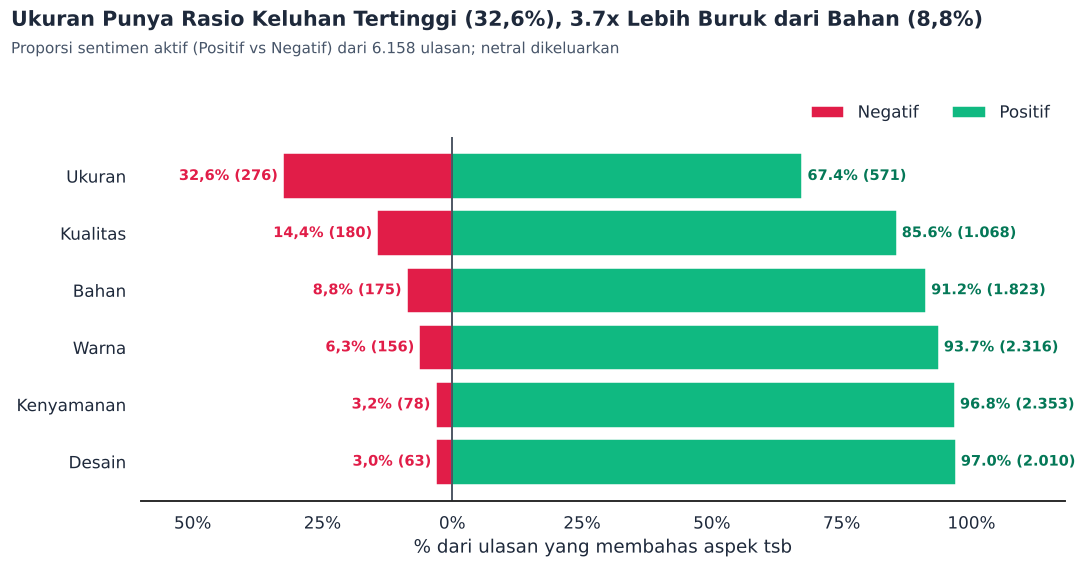

In [7]:
def plot_diverging(m):
    m = m.sort_values("ANR (%)", ascending=True)          # barh: ANR tertinggi berada di atas
    tot = m["Ulasan Aktif"]; neg_p = m["Negatif"]/tot*100; pos_p = m["Positif"]/tot*100
    fig, ax = plt.subplots(figsize=(10, 5.2))
    ax.barh(m["Aspek"], -neg_p, color=NEG, label="Negatif")
    ax.barh(m["Aspek"], pos_p, color=POS, label="Positif")
    for i, (n_, p_, nn, pp) in enumerate(zip(neg_p, pos_p, m["Negatif"], m["Positif"])):
        ax.text(-n_-1, i, f"{pct(n_)} ({nn})", ha="right", va="center", fontsize=9.5, color=NEG, fontweight="bold")
        ax.text(p_+1, i, f"{pct(p_)} ({pp:,})".replace(",", "."), ha="left", va="center", fontsize=9.5, color="#047857", fontweight="bold")
    ax.axvline(0, color=INK, lw=1); ax.set_xlim(-60, 118); ax.set_xticks(range(-50, 101, 25))
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{abs(x):.0f}%")); ax.set_xlabel("% dari ulasan yang membahas aspek tsb")
    ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2); sns.despine(left=True)
    top, nxt = m.iloc[-1], m.iloc[-2]
    titled(fig, f"{top['Aspek']} Punya Rasio Keluhan Tertinggi ({pct(top['ANR (%)'])}), {top['ANR (%)']/m.loc[m['Aspek']=='Bahan','ANR (%)'].iloc[0]:.1f}x Lebih Buruk dari Bahan ({pct(m.loc[m['Aspek']=='Bahan','ANR (%)'].iloc[0])})",
           f"Proporsi sentimen aktif (Positif vs Negatif) dari {len(df):,} ulasan; netral dikeluarkan".replace(",", "."))
    fig.tight_layout(rect=[0, 0, 1, 0.86]); plt.show()
plot_diverging(metrics)

🔍 **Key Observation:** Ukuran dan Kualitas adalah dua aspek dengan sisi merah terpanjang; Desain dan Kenyamanan paling aman. Urutan ANR: Ukuran 32,6%, Kualitas 14,4%, Bahan 8,8%, Warna 6,3%, Kenyamanan 3,2%, Desain 3,0%.

💡 **Business Insight (So What?):** Aspek 'emosional' (desain, kenyamanan, warna) kuat, sedangkan aspek 'ekspektasi fisik' (ukuran, kualitas) rawan kecewa  konsisten dengan pola belanja online tanpa coba langsung.

🎯 **Next Action:** Fokuskan sumber daya perbaikan pada dua aspek teratas; jangan ubah desain yang sudah jadi kekuatan.

### 2.2 Strategic quadrant  Mention Rate × NSS

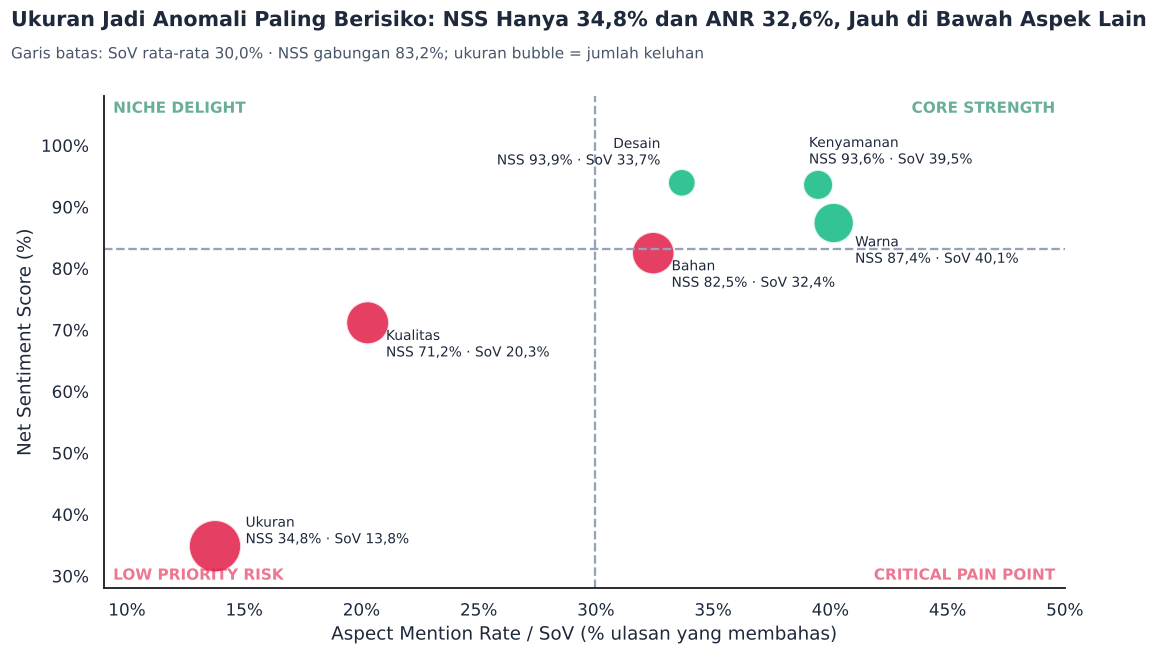

,Aspek,SoV (%),NSS (%),Kuadran
0,Ukuran,13.8%,34.8%,Low Priority Risk
1,Kualitas,20.3%,71.2%,Low Priority Risk
2,Bahan,32.4%,82.5%,Critical Pain Point
3,Warna,40.1%,87.4%,Core Strength
4,Kenyamanan,39.5%,93.6%,Core Strength
5,Desain,33.7%,93.9%,Core Strength


In [8]:
def plot_quadrant(m):
    x_thr = m["SoV (%)"].mean()
    p, n = m["Positif"].sum(), m["Negatif"].sum(); y_thr = (p - n) / (p + n) * 100     # NSS gabungan
    def quad(r):
        hi_x, hi_y = r["SoV (%)"] >= x_thr, r["NSS (%)"] >= y_thr
        return ("Core Strength" if hi_x and hi_y else "Critical Pain Point" if hi_x else "Niche Delight" if hi_y else "Low Priority Risk")
    m = m.assign(Kuadran=m.apply(quad, axis=1))
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.scatter(m["SoV (%)"], m["NSS (%)"], s=m["Negatif"]*4+80, c=[NEG if k in ("Critical Pain Point","Low Priority Risk") else POS for k in m["Kuadran"]], alpha=.85, edgecolor="white", lw=1.5)
    OFF = {"Ukuran": (20, 2), "Desain": (-14, 12), "Kenyamanan": (-6, 14), "Warna": (14, -26)}
    for _, r in m.iterrows():
        ax.annotate(f"{r['Aspek']}\nNSS {pct(r['NSS (%)'])} · SoV {pct(r['SoV (%)'])}", (r["SoV (%)"], r["NSS (%)"]), textcoords="offset points", xytext=OFF.get(r["Aspek"], (12, -22)), fontsize=9, ha=("left" if r["Aspek"] != "Desain" else "right"))
    ax.axvline(x_thr, color=NEU, ls="--"); ax.axhline(y_thr, color=NEU, ls="--")
    ax.set_xlim(9, 50); ax.set_ylim(28, 108)
    for (xx, yy, ha, va, t, col) in [(.99, .99, "right", "top", "CORE STRENGTH", "#047857"), (.99, .01, "right", "bottom", "CRITICAL PAIN POINT", NEG),
                                     (.01, .99, "left", "top", "NICHE DELIGHT", "#047857"), (.01, .01, "left", "bottom", "LOW PRIORITY RISK", NEG)]:
        ax.text(xx, yy, t, transform=ax.transAxes, ha=ha, va=va, color=col, fontweight="bold", alpha=.6, fontsize=10)
    ax.set_xlabel("Aspect Mention Rate / SoV (% ulasan yang membahas)"); ax.set_ylabel("Net Sentiment Score (%)")
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    sns.despine()
    uk = m[m["Aspek"] == "Ukuran"].iloc[0]
    titled(fig, f"Ukuran Jadi Anomali Paling Berisiko: NSS Hanya {pct(uk['NSS (%)'])} dan ANR {pct(uk['ANR (%)'])}, Jauh di Bawah Aspek Lain",
           f"Garis batas: SoV rata-rata {pct(x_thr)} · NSS gabungan {pct(y_thr)}; ukuran bubble = jumlah keluhan")
    fig.tight_layout(rect=[0, 0, 1, 0.88]); plt.show(); return m
mq = plot_quadrant(metrics)
display(mq[["Aspek", "SoV (%)", "NSS (%)", "Kuadran"]].style.format({"SoV (%)":"{:.1f}%","NSS (%)":"{:.1f}%"}))
M["anr_urut"] = ", ".join(f"{a} {pct(v)}" for a, v in zip(metrics["Aspek"], metrics["ANR (%)"]))
M["quad_ukuran"] = mq.set_index("Aspek").loc["Ukuran", "Kuadran"]; M["quad_bahan"] = mq.set_index("Aspek").loc["Bahan", "Kuadran"]; M["nss_bahan"] = pct(u.loc["Bahan","NSS (%)"])

🔍 **Key Observation:** Desain, Warna, dan Kenyamanan masuk area kekuatan (NSS tinggi). Bahan tepat di garis batas (NSS 82,5%, kuadran Critical Pain Point). Kualitas jauh di bawah garis NSS. Ukuran terpisah jauh di bawah: dibahas jarang tetapi NSS jauh paling rendah; menurut aturan 2×2 ia jatuh ke kuadran Low Priority Risk.

💡 **Business Insight (So What?):** Label 'Low Priority' menyesatkan untuk Ukuran: volumenya kecil karena tidak semua orang menulis soal ukuran, tapi ia #1 pada ANR dan WPI. Kita menganggapnya **prioritas tinggi** meski aturan kuadran menaruhnya di sisi mention rendah.

🎯 **Next Action:** Perlakukan Ukuran sebagai 'hidden critical pain point'. Pantau NSS Ukuran bulanan sebagai KPI utama produk.

---
## 📌 Section 3  Hidden Dissatisfaction & Rating–Sentiment Paradox
Karena `pola_ulasan` aktual hanya `terstruktur/bebas`, segmen perilaku di bawah **diturunkan dari definisi di brief** (Rating × aspek).

In [9]:
dr = df.dropna(subset=["Rating"]).copy()
dr["Rating"] = dr["Rating"].astype(int)
dr["Segmen"] = np.select(
    [(dr.Rating >= 4) & (dr.n_neg > 0), (dr.Rating <= 2) & (dr.n_neg == 0) & (dr.n_pos > 0),
     (dr.Rating >= 4) & (dr.n_neg == 0), (dr.Rating <= 2) & (dr.n_neg > 0)],
    ["Komplain_Di_Rating_Tinggi", "Rating_Rendah_Teks_Positif", "Puas_Konsisten", "Kecewa_Konsisten"], default="Lainnya (★3 / netral)")
seg = pd.crosstab(dr["Segmen"], dr["Rating"], margins=True, margins_name="Total")
display(seg)
print("\npola_ulasan (format penulisan) x Rating:"); display(pd.crosstab(df["pola_ulasan"], df["Rating"], margins=True))
M["n_komplain_tinggi"] = num((dr.Segmen=="Komplain_Di_Rating_Tinggi").sum()); M["n_rr_tp"] = int((dr.Segmen=="Rating_Rendah_Teks_Positif").sum())

Rating,1,2,3,4,5,Total
Segmen,,,,,,
Kecewa_Konsisten,116,77,0,0,0,193
Komplain_Di_Rating_Tinggi,0,0,0,112,340,452
Lainnya (★3 / netral),26,12,224,0,0,262
Puas_Konsisten,0,0,0,418,4796,5214
Rating_Rendah_Teks_Positif,7,9,0,0,0,16
Total,149,98,224,530,5136,6137



pola_ulasan (format penulisan) x Rating:


Rating,1.0,2.0,3.0,4.0,5.0,All
pola_ulasan,,,,,,
bebas,87,65,142,250,1967,2511
terstruktur,62,33,82,280,3169,3626
All,149,98,224,530,5136,6137


### 3.1 Hidden Dissatisfaction Rate (HDR)

HDR ★5   = 340 / 5,136 = 6,6%
HDR ★4–5 = 452 / 5,666 = 8,0%


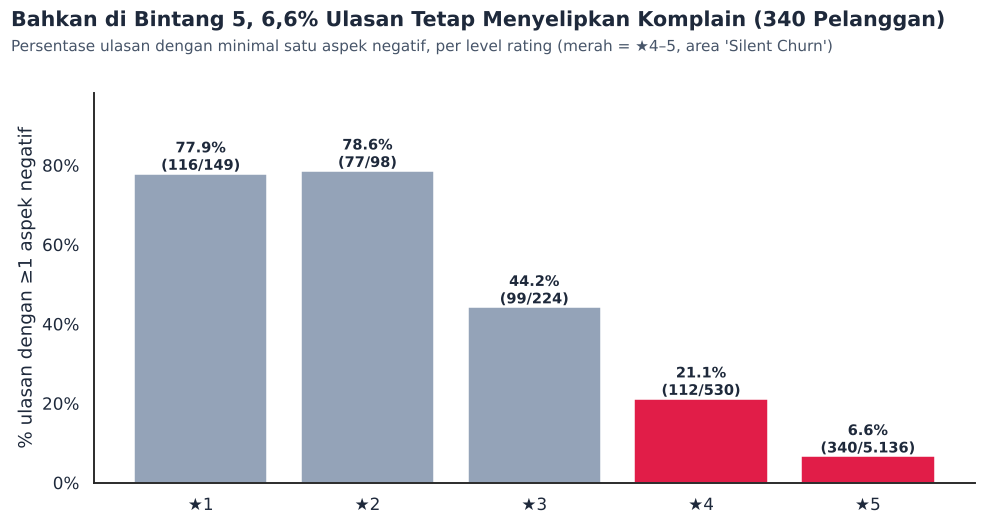

In [10]:
def hdr(d, ratings):
    s = d[d.Rating.isin(ratings)]; return int((s.n_neg > 0).sum()), len(s)
n5, t5 = hdr(dr, [5]); n45, t45 = hdr(dr, [4, 5])
print(f"HDR ★5   = {n5} / {t5:,} = {pct(n5/t5*100)}")
print(f"HDR ★4–5 = {n45} / {t45:,} = {pct(n45/t45*100)}")
M.update(hdr5=pct(n5/t5*100), hdr5_n=num(n5), n_r5=num(t5), hdr45_n=num(n45), hdr45=pct(n45/t45*100))
assert (n5, t5) == (340, 5136)

by_r = dr.groupby("Rating").apply(lambda s: pd.Series({"n": len(s), "n_komplain": int((s.n_neg>0).sum())}))
by_r["pct"] = by_r.n_komplain / by_r.n * 100
fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.bar([f"★{r}" for r in by_r.index], by_r.pct, color=[NEG if r >= 4 else NEU for r in by_r.index])
for b, (_, r) in zip(bars, by_r.iterrows()):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+1, f"{pct(r.pct)}\n({int(r.n_komplain)}/{int(r.n):,})".replace(",", "."), ha="center", fontsize=9.5, fontweight="bold")
ax.set_ylim(0, by_r.pct.max()*1.25); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.set_ylabel("% ulasan dengan ≥1 aspek negatif"); sns.despine()
titled(fig, f"Bahkan di Bintang 5, {pct(n5/t5*100)} Ulasan Tetap Menyelipkan Komplain ({n5} Pelanggan)",
       "Persentase ulasan dengan minimal satu aspek negatif, per level rating (merah = ★4–5, area 'Silent Churn')")
fig.tight_layout(rect=[0, 0, 1, 0.86]); plt.show()

🔍 **Key Observation:** HDR ★5 = 6,6% (340 dari 5.136 ulasan); untuk ★4–5 total 452 ulasan berkomplain.

💡 **Business Insight (So What?):** Rating tinggi tidak sama dengan 'tanpa masalah'. Pembeli sopan memberi ★5 sambil mengeluh; mereka kandidat *silent churn* karena tidak diberi sinyal oleh rating.

🎯 **Next Action:** CS/CRM: tandai ulasan ★4–5 dengan aspek negatif untuk follow-up proaktif (tukar ukuran, voucher). Tambahkan HDR ke dashboard mingguan.

### 3.2 Anatomy of a 5-Star (and 4-Star) Complaint

,Negatif di ★4–5,Total Negatif,% dari seluruh keluhan aspek itu,Share dalam keluhan ★4–5
Ukuran,201,276,72.8%,39.9%
Bahan,104,175,59.4%,20.6%
Kualitas,74,180,41.1%,14.7%
Warna,55,156,35.3%,10.9%
Kenyamanan,51,78,65.4%,10.1%
Desain,19,63,30.2%,3.8%


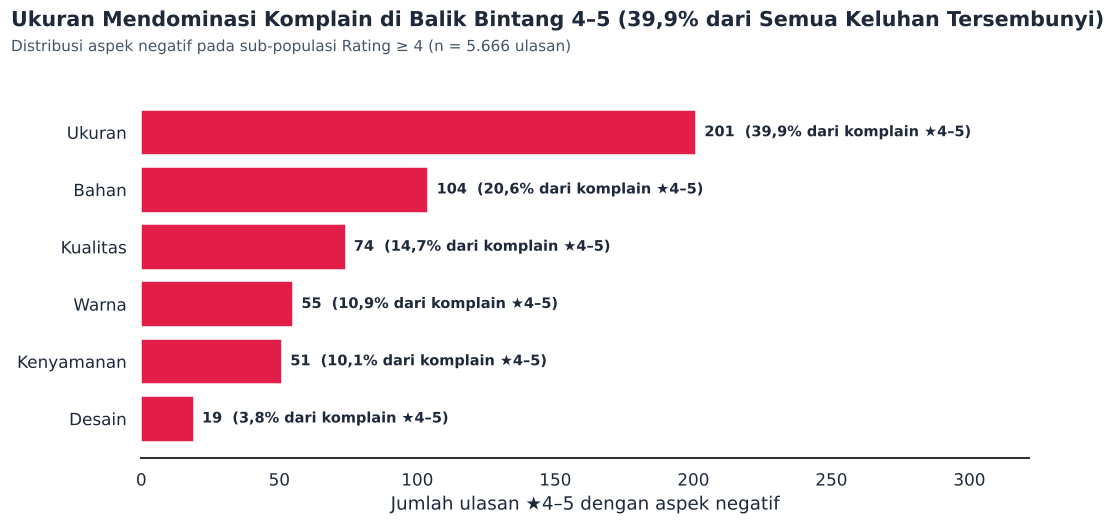

In [11]:
hi = dr[dr.Rating >= 4]
neg_hi = (hi[A] == "negatif").sum().rename(index=nice)
neg_all = (df[A] == "negatif").sum().rename(index=nice)
anat = pd.DataFrame({"Negatif di ★4–5": neg_hi, "Total Negatif": neg_all})
anat["% dari seluruh keluhan aspek itu"] = anat.iloc[:,0] / anat.iloc[:,1] * 100
anat["Share dalam keluhan ★4–5"] = anat.iloc[:,0] / anat.iloc[:,0].sum() * 100
anat = anat.sort_values("Negatif di ★4–5", ascending=False)
display(anat.style.format({"Negatif di ★4–5":"{:,.0f}","Total Negatif":"{:,.0f}","% dari seluruh keluhan aspek itu":"{:.1f}%","Share dalam keluhan ★4–5":"{:.1f}%"}))
M["ukuran_hidden_share"] = pct(anat.loc["Ukuran","% dari seluruh keluhan aspek itu"]); M["top_hidden"] = anat.index[0]
M["ukuran_hi_share"] = pct(anat.loc["Ukuran","Share dalam keluhan ★4–5"])

fig, ax = plt.subplots(figsize=(9.5, 4.8)); a2 = anat.sort_values("Negatif di ★4–5")
bars = ax.barh(a2.index, a2["Negatif di ★4–5"], color=NEG)
for b, (_, r) in zip(bars, a2.iterrows()):
    ax.text(b.get_width()+3, b.get_y()+b.get_height()/2, f"{int(r.iloc[0])}  ({pct(r['Share dalam keluhan ★4–5'])} dari komplain ★4–5)", va="center", fontsize=9.5, fontweight="bold")
ax.set_xlim(0, a2.iloc[:,0].max()*1.6); ax.set_xlabel("Jumlah ulasan ★4–5 dengan aspek negatif"); sns.despine(left=True)
titled(fig, f"{anat.index[0]} Mendominasi Komplain di Balik Bintang 4–5 ({M['ukuran_hi_share']} dari Semua Keluhan Tersembunyi)",
       f"Distribusi aspek negatif pada sub-populasi Rating ≥ 4 (n = {len(hi):,} ulasan)".replace(",", "."))
fig.tight_layout(rect=[0, 0, 1, 0.86]); plt.show()

🔍 **Key Observation:** Aspek yang paling sering 'dimaafkan' namun tetap dikeluhkan adalah Ukuran: 72,8% keluhan Ukuran berasal dari pembeli ★4–5.

💡 **Business Insight (So What?):** Pembeli menilai produk (bahan, desain) bagus sehingga memberi bintang tinggi, tetapi ukuran meleset. Di sinilah **silent churn**: sopan hari ini, tidak repeat order bulan depan bila size tidak pas.

🎯 **Next Action:** Tambahkan panduan 'size up/size down' langsung di listing dan template chat pasca-order yang menanyakan kecocokan ukuran.

### 3.3 Anomali sebaliknya  Rating rendah (★1–2) tetapi tanpa aspek negatif

In [12]:
lowpos = dr[(dr.Rating <= 2) & (dr.n_neg == 0)].copy()
print(f"★1–2 tanpa aspek negatif: {len(lowpos)} ulasan; di antaranya {int((lowpos.n_pos>0).sum())} bernilai positif pada ≥1 aspek (= segmen Rating_Rendah_Teks_Positif),"
      f" dan {int((lowpos.n_pos==0).sum())} tidak memiliki aspek aktif sama sekali.")

CAUSES = [  # urutan = prioritas pencocokan
 ("Salah / kurang barang",            r"salah (kirim|barang|warna|ukuran)|kurang (1|satu)|cuma(n)? (1|satu)|tidak sesuai (pesanan|dengan (yang|yg) (di)?pesan)|tertinggal|ketinggalan|barang(nya)? (datang )?(cuma|hanya)|tidak sampai|baru (di)?kabari"),
 ("Kemasan",                          r"kemas|packing|packaging|bungkus|dus |bekas (di)?buka"),
 ("Pelayanan admin / penjual",        r"admin|penjual|seller|respon|\bcs\b|balas|pelayanan|ramah|picking|retur|return|batalkan|tagih"),
 ("Pengiriman",                       r"kirim|kurir|nyampe|sampai|\blama\b|telat|terlambat|ekspedisi|resi"),
 ("Cacat / kondisi barang (keluhan kualitas tak terlabeli)",           r"cacat|defect|diffect|reject|noda|rusak|lepas|kancing|sobek|bolong|lecek|bekas|benang|jahit|burik|kusut"),
 ("Ukuran / fit (keluhan ukuran tak terlabeli)",     r"ukuran|\bsize|pinggang|kecil|besar|ngepas|sempit"),
 ("Tidak sesuai deskripsi / ekspektasi (tak terlabeli)", r"tidak sesuai|deskripsi|foto|gambar|beda|over|tidak seperti"),
 ("Harga / promo",                    r"harga|mahal|promo|free|hadiah|diskon|brand"),
]
def classify_cause(text):
    t = str(text).lower()
    for name, pat in CAUSES:
        if re.search(pat, t): return name
    return "Tidak jelas (indikasi salah pencet bintang / teks terlalu pendek)"
lowpos["Penyebab"] = lowpos["Comment"].map(classify_cause)
cause_tab = lowpos["Penyebab"].value_counts().rename_axis("Penyebab").reset_index(name="Jumlah")
cause_tab["%"] = cause_tab["Jumlah"] / cause_tab["Jumlah"].sum() * 100
display(cause_tab.style.format({"%":"{:.1f}%"}))
OUT = ["Salah / kurang barang","Kemasan","Pelayanan admin / penjual","Pengiriman","Harga / promo"]
nonprod = cause_tab[cause_tab.Penyebab.isin(OUT)]["Jumlah"].sum()
inasp = cause_tab[cause_tab.Penyebab.str.contains("tak terlabeli")]["Jumlah"].sum()
unclear = cause_tab[cause_tab.Penyebab.str.startswith("Tidak jelas")]["Jumlah"].sum()
M["lowpos_n"] = len(lowpos); M["lowpos_nonprod"] = pct(nonprod / len(lowpos) * 100); M["lowpos_nonprod_n"] = int(nonprod)
M["lowpos_inasp"] = pct(inasp / len(lowpos) * 100); M["lowpos_inasp_n"] = int(inasp); M["lowpos_unclear"] = pct(unclear / len(lowpos) * 100)

smp = lowpos[lowpos.n_pos > 0].head(10)[["Rating", "Comment", "Penyebab"]].copy()
smp["Comment"] = smp["Comment"].str.replace(r"\s+", " ", regex=True).str.slice(0, 170)
print("\n10 sampel Rating_Rendah_Teks_Positif (aspek terdeteksi positif) + kategori penyebab:")
display(smp.reset_index(drop=True))

★1–2 tanpa aspek negatif: 54 ulasan; di antaranya 16 bernilai positif pada ≥1 aspek (= segmen Rating_Rendah_Teks_Positif), dan 38 tidak memiliki aspek aktif sama sekali.


,Penyebab,Jumlah,%
0,Pelayanan admin / penjual,11,20.4%
1,Tidak jelas (indikasi salah pencet bintang / teks terlalu pendek),11,20.4%
2,Cacat / kondisi barang (keluhan kualitas tak terlabeli),10,18.5%
3,Ukuran / fit (keluhan ukuran tak terlabeli),7,13.0%
4,Pengiriman,6,11.1%
5,Salah / kurang barang,3,5.6%
6,Tidak sesuai deskripsi / ekspektasi (tak terlabeli),3,5.6%
7,Harga / promo,2,3.7%
8,Kemasan,1,1.9%



10 sampel Rating_Rendah_Teks_Positif (aspek terdeteksi positif) + kategori penyebab:


,Rating,Comment,Penyebab
0,2,"Berat:lumayan Warna:sesuai Saya pesan sesuai ukuran di deskripsinya no 42 ut uk 27,5 dan datengnya sesuai tapi terlalu ngepas kak di kaki",Ukuran / fit (keluhan ukuran tak terlabeli)
1,2,Berat:pas Warna:sesuai Kenyamanan:empuk,Tidak jelas (indikasi salah pencet bintang / teks terlalu pendek)
2,1,Pas untuk Acara:gak pas.dikarenakan barang tidak sesuai dengan keinginan Sepadan dengan Uang:lumayan Kenyamanan:nyaman sih Pengiriman yang cukup lama,Pengiriman
3,2,"pembelelian pertama oke sesuai dari warna(grey) ukuran,kain pas pembelian kedua bahan oke,warna oke,tapi gagal dari soal ukuran nya padahal pesen nya sama c...",Ukuran / fit (keluhan ukuran tak terlabeli)
4,1,"Pas untuk Acara:buruk tidak sesuai dengan yg di pesan. pada saat pengajuan pengembalian dan melakukan komplain, admin bilang kalau itu gift, dan menyarankan...",Pelayanan admin / penjual
5,2,"Pertama kali beli di store erigo, kemeja nya ngak banget, entah kenapa dapat yg kurang memuaskan, sisa benang banyak, jahitan ngk rapi, klo sisa benang dita...",Cacat / kondisi barang (keluhan kualitas tak terlabeli)
6,1,"Aneh bgt ni erigo, ga ada standar buat ukuran, saya pernah beli kemeja ukuran M dan pas di badan saya, sekarang ukuran M nya kayak XL. Ga jelas bg rugi bela...",Ukuran / fit (keluhan ukuran tak terlabeli)
7,1,"Kenyamanan:ku ng tau ukuran 33 seperti apa emng ukurannya begini, tapi ini celana pas datang pingangnya kecil bangett pdhl pinggang aku termasuk ramping cek...",Ukuran / fit (keluhan ukuran tak terlabeli)
8,1,Warna:sesuai Bahan:sesuai dengan foto Tdk sesuai dgn deskripsi keterangan produk ukuran pinggang d deskripsi 74 cm pas dtng d ukur 84 cm,Ukuran / fit (keluhan ukuran tak terlabeli)
9,2,"Gajelas sizenya , di foto size chat sama yg di pas co itu beda, bingung pilih mana, pilih 31 malah kegedeaan gajelah",Ukuran / fit (keluhan ukuran tak terlabeli)


🔍 **Key Observation:** Dari 54 ulasan ★1–2 tanpa aspek negatif, **42,6% (23 ulasan)** berisi masalah **di luar 6 aspek** (salah/kurang barang, kemasan, admin, pengiriman, harga). Lainnya 20 ulasan (37,0%) adalah keluhan ukuran/cacat/ketidaksesuaian yang *tidak terlabeli negatif*, dan hanya 20,4% yang tidak jelas (kandidat salah pencet bintang).

💡 **Business Insight (So What?):** Rating rendah berteks 'positif' hampir tidak pernah salah pencet. Ada dua penyebab: (1) **blind spot taksonomi**  keluhan layanan/pengiriman tidak punya aspek; (2) **under-labeling**  sebagian keluhan ukuran/cacat tidak ditandai negatif (noise label; NSS Ukuran/Kualitas kemungkinan *under-estimated*).

🎯 **Next Action:** Tim Data: tambahkan aspek pengiriman, kemasan, pelayanan (Section 6) dan audit ulang label ukuran/kualitas pada ulasan ★1–2. Tim Ops: eskalasi kasus salah/kurang barang dan respons admin.

---
## 📌 Section 4  Multi-Aspect Co-Occurrence & Halo/Horn Effect
### 4.1 Encoding numerik, co-occurrence & conditional probability

In [13]:
MAP = {"positif": 1, "netral": 0, "negatif": -1}
Z = df[A].apply(lambda s: s.map(MAP)); Z.columns = [nice(a) for a in A]          # numerik terarah
NEGB = (df[A] == "negatif").astype(int); NEGB.columns = Z.columns                 # biner negatif
MENT = (df[A] != "netral").astype(int); MENT.columns = Z.columns                  # biner mention

cooc_neg = NEGB.T @ NEGB
cond = cooc_neg.div(np.diag(cooc_neg), axis=0)         # baris i, kolom j = P(j negatif | i negatif)
base = NEGB.mean()
print("Matriks co-occurrence keluhan (jumlah ulasan yang memuat keduanya negatif):"); display(cooc_neg)
print("Korelasi Spearman antar-aspek (skala -1/0/+1):"); display(Z.corr(method="spearman").style.background_gradient(cmap="RdBu", vmin=-.5, vmax=.5).format("{:.2f}"))

def P(a, b, va="negatif", vb="negatif"): 
    s = df[df[f"aspek_{a}"] == va]; return (s[f"aspek_{b}"] == vb).mean() * 100
p1, p2 = P("bahan","kenyamanan"), P("ukuran","kenyamanan"); p3 = P("ukuran","kualitas","negatif","positif"); p4 = P("bahan","kualitas")
p5 = P("ukuran","kualitas"); p6 = P("ukuran","kualitas","negatif","netral")
M.update(p_kenyam_bahan=pct(p1), b_kenyam=pct(base["Kenyamanan"]*100), p_kenyam_ukuran=pct(p2), p_kual_ukuran_pos=pct(p3), p_kual_bahan=pct(p4), b_kual=pct(base["Kualitas"]*100), p_kual_ukuran_neg=pct(p5), p_kual_ukuran_net=pct(p6))
print(f"\nP(Kenyamanan negatif | Bahan negatif)    = {pct(p1)}   (baseline {pct(base['Kenyamanan']*100)})")
print(f"P(Kualitas  negatif | Bahan negatif)     = {pct(p4)}   (baseline {pct(base['Kualitas']*100)})")
print(f"P(Kenyamanan negatif | Ukuran negatif)   = {pct(p2)}")
print(f"P(Kualitas positif  | Ukuran negatif)    = {pct(p3)}   ; P(Kualitas negatif | Ukuran negatif) = {pct(p5)}")

Matriks co-occurrence keluhan (jumlah ulasan yang memuat keduanya negatif):


,Kualitas,Bahan,Ukuran,Desain,Warna,Kenyamanan
Kualitas,180,20,20,11,33,6
Bahan,20,175,14,10,16,15
Ukuran,20,14,276,8,23,10
Desain,11,10,8,63,22,8
Warna,33,16,23,22,156,11
Kenyamanan,6,15,10,8,11,78


Korelasi Spearman antar-aspek (skala -1/0/+1):


,Kualitas,Bahan,Ukuran,Desain,Warna,Kenyamanan
Kualitas,1.00,0.01,0.05,0.09,-0.04,0.03
Bahan,0.01,1.00,0.04,0.11,-0.07,0.17
Ukuran,0.05,0.04,1.00,0.03,0.07,0.07
Desain,0.09,0.11,0.03,1.00,0.32,0.09
Warna,-0.04,-0.07,0.07,0.32,1.00,0.26
Kenyamanan,0.03,0.17,0.07,0.09,0.26,1.00



P(Kenyamanan negatif | Bahan negatif)    = 8,6%   (baseline 1,3%)
P(Kualitas  negatif | Bahan negatif)     = 11,4%   (baseline 2,9%)
P(Kenyamanan negatif | Ukuran negatif)   = 3,6%
P(Kualitas positif  | Ukuran negatif)    = 7,2%   ; P(Kualitas negatif | Ukuran negatif) = 7,2%


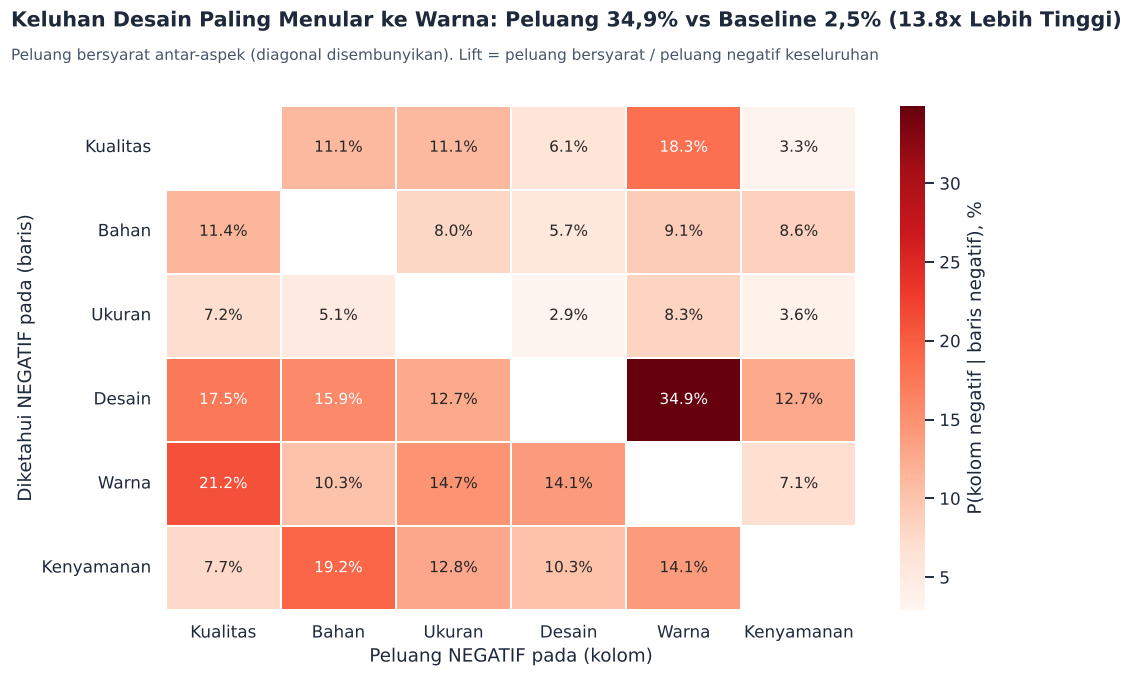

In [14]:
fig, ax = plt.subplots(figsize=(9.5, 6.2))
annot = cond.mul(100).round(1).astype(str) + "%"
mask = np.eye(len(cond), dtype=bool)
sns.heatmap(cond * 100, mask=mask, annot=annot, fmt="", cmap="Reds", cbar_kws={"label": "P(kolom negatif | baris negatif), %"}, linewidths=1, linecolor="white", ax=ax)
ax.set_ylabel("Diketahui NEGATIF pada (baris)"); ax.set_xlabel("Peluang NEGATIF pada (kolom)"); plt.setp(ax.get_yticklabels(), rotation=0)
pairs = [(i, j, cond.loc[i, j] * 100, base[j] * 100) for i in cond.index for j in cond.columns if i != j]
bi, bj, bv, bb = max(pairs, key=lambda t: t[2] / t[3])
titled(fig, f"Keluhan {bi} Paling Menular ke {bj}: Peluang {pct(bv)} vs Baseline {pct(bb)} ({bv/bb:.1f}x Lebih Tinggi)",
       "Peluang bersyarat antar-aspek (diagonal disembunyikan). Lift = peluang bersyarat / peluang negatif keseluruhan")
fig.tight_layout(rect=[0, 0, 1, 0.87]); plt.show()
M.update(horn_pair=f"{bi}→{bj}", horn_p=pct(bv), horn_b=pct(bb), horn_lift=f"{bv/bb:.1f}".replace(".", ","))

🔍 **Key Observation:** Keluhan tidak berdiri sendiri: pasangan terkuat adalah Desain→Warna (P = 34,9% vs baseline 2,5%, lift 13,8x). P(Kualitas negatif | Bahan negatif) = 11,4% (baseline 2,9%); P(Kenyamanan negatif | Bahan negatif) = 8,6% (baseline 1,3%).

💡 **Business Insight (So What?):** Ada Horn Effect: satu cacat menaikkan peluang aspek lain ikut buruk. Sebaliknya, dari pelanggan yang mengeluh Ukuran hanya 7,2% yang juga menilai Kualitas negatif dan 7,2% yang menilainya positif; pada 85,5% pelanggan yang mengeluh Ukuran, Kualitas tidak dibahas sama sekali. Keluhan ukuran terasa **terisolasi** (masalah kecocokan), bukan tanda produk jelek.

🎯 **Next Action:** Selesaikan Bahan/Kualitas sebagai satu paket QC; untuk Ukuran gunakan solusi informasi (size chart), bukan perubahan material.

### 4.2 Apakah pelanggan kecewa menulis lebih panjang & membahas lebih banyak aspek?

,Variabel,Pembanding,Median (kiri),Median ★4–5 puas,Kruskal-Wallis p,Mann-Whitney p,Effect size (rank-biserial)
0,panjang_kata,★4–5 + komplain vs ★4–5 puas,15.0,10.0,1.63e-32,2.13e-31,+0.33
1,panjang_kata,Rating ★1–3 vs ★4–5 puas,11.0,10.0,1.63e-32,1.17e-05,+0.12
2,jumlah_aspek_aktif,★4–5 + komplain vs ★4–5 puas,2.0,2.0,3.03e-39,8.31e-13,+0.20
3,jumlah_aspek_aktif,Rating ★1–3 vs ★4–5 puas,1.0,2.0,3.03e-39,3.32e-26,-0.28


Kontrol (hanya ulasan berlabel): jumlah_aspek_aktif, ada-negatif vs tanpa-negatif -> p=1.87e-07, effect=-0.11, median 2 vs 2


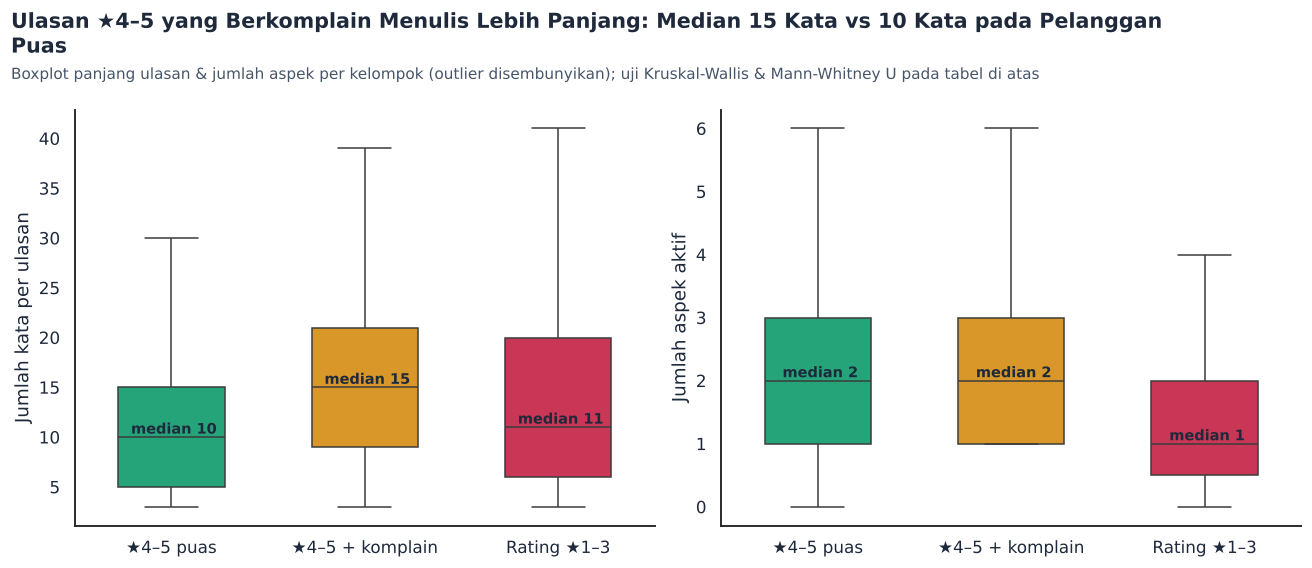

In [15]:
d3 = dr.copy()
d3["Kelompok"] = np.select([d3.Rating <= 3, (d3.Rating >= 4) & (d3.n_neg > 0)], ["Rating ★1–3", "★4–5 + komplain"], default="★4–5 puas")
ORDER = ["★4–5 puas", "★4–5 + komplain", "Rating ★1–3"]
d3["Kelompok"] = pd.Categorical(d3["Kelompok"], ORDER, ordered=True)

def rank_biserial(x, y):
    """p-value Mann-Whitney U & rank-biserial r (positif = x cenderung lebih besar dari y)."""
    u = stats.mannwhitneyu(x, y, alternative="two-sided"); return u.pvalue, 2 * u.statistic / (len(x) * len(y)) - 1
rows = []
for var in ["panjang_kata", "jumlah_aspek_aktif"]:
    g = [d3.loc[d3.Kelompok == k, var] for k in ORDER]
    kw = stats.kruskal(*g)
    for k in ORDER[1:]:
        p, rbc = rank_biserial(d3.loc[d3.Kelompok == k, var], d3.loc[d3.Kelompok == "★4–5 puas", var])
        rows.append({"Variabel": var, "Pembanding": f"{k} vs ★4–5 puas", "Median (kiri)": d3.loc[d3.Kelompok == k, var].median(),
                     "Median ★4–5 puas": d3.loc[d3.Kelompok == "★4–5 puas", var].median(), "Kruskal-Wallis p": kw.pvalue, "Mann-Whitney p": p, "Effect size (rank-biserial)": rbc})
tests = pd.DataFrame(rows)
display(tests.style.format({"Median (kiri)":"{:.1f}","Median ★4–5 puas":"{:.1f}","Kruskal-Wallis p":"{:.2e}","Mann-Whitney p":"{:.2e}","Effect size (rank-biserial)":"{:+.2f}"}))

lab = d3[d3.memiliki_label]       # kontrol: jumlah_aspek secara mekanis >=1 bila ada aspek negatif -> bandingkan hanya ulasan berlabel
p_ctrl, r_ctrl = rank_biserial(lab.loc[lab.n_neg > 0, "jumlah_aspek_aktif"], lab.loc[lab.n_neg == 0, "jumlah_aspek_aktif"])
print(f"Kontrol (hanya ulasan berlabel): jumlah_aspek_aktif, ada-negatif vs tanpa-negatif -> p={p_ctrl:.2e}, effect={r_ctrl:+.2f}, "
      f"median {lab.loc[lab.n_neg>0,'jumlah_aspek_aktif'].median():.0f} vs {lab.loc[lab.n_neg==0,'jumlah_aspek_aktif'].median():.0f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
pal = {"★4–5 puas": POS, "★4–5 + komplain": "#F59E0B", "Rating ★1–3": NEG}
for ax, var, lbl in zip(axes, ["panjang_kata", "jumlah_aspek_aktif"], ["Jumlah kata per ulasan", "Jumlah aspek aktif"]):
    sns.boxplot(data=d3, x="Kelompok", y=var, palette=pal, showfliers=False, ax=ax, width=.55)
    for i, k in enumerate(ORDER):
        med = d3.loc[d3.Kelompok == k, var].median(); ax.text(i, med, f" median {med:.0f}", ha="center", va="bottom", fontsize=9.5, fontweight="bold", color=INK)
    ax.set_xlabel(""); ax.set_ylabel(lbl); sns.despine(ax=ax)
mp = {k: d3.loc[d3.Kelompok == k, "panjang_kata"].median() for k in ORDER}
titled(fig, f"Ulasan ★4–5 yang Berkomplain Menulis Lebih Panjang: Median {mp['★4–5 + komplain']:.0f} Kata vs {mp['★4–5 puas']:.0f} Kata pada Pelanggan Puas",
       "Boxplot panjang ulasan & jumlah aspek per kelompok (outlier disembunyikan); uji Kruskal-Wallis & Mann-Whitney U pada tabel di atas")
fig.tight_layout(rect=[0, 0, 1, 0.84]); plt.show()
ma = {k: d3.loc[d3.Kelompok == k, "jumlah_aspek_aktif"].median() for k in ORDER}
M.update(med_asp_hid=f"{ma['★4–5 + komplain']:.0f}", med_asp_low=f"{ma['Rating ★1–3']:.0f}", med_asp_happy=f"{ma['★4–5 puas']:.0f}")
M.update(med_len_low=f"{mp['Rating ★1–3']:.0f}", med_len_happy=f"{mp['★4–5 puas']:.0f}", med_len_hid=f"{mp['★4–5 + komplain']:.0f}",
         kw_len=f"{stats.kruskal(*[d3.loc[d3.Kelompok==k,'panjang_kata'] for k in ORDER]).pvalue:.1e}")

🔍 **Key Observation:** Median panjang ulasan: ★4–5 puas 10 kata, ★4–5 berkomplain 15 kata (signifikan; Kruskal-Wallis p = 1.6e-32, effect size sedang +0,33). **Hipotesis brief hanya sebagian terbukti:** pelanggan ★1–3 hanya sedikit lebih panjang (median 11 kata, effect kecil +0,12) dan justru membahas *lebih sedikit* aspek (median 1 vs 2). Pada ulasan berlabel, ulasan beraspek negatif juga tidak membahas lebih banyak aspek (effect −0,11; kontrol di atas).

💡 **Business Insight (So What?):** Yang menulis panjang adalah pembeli yang **puas tetapi berkomplain** (★4–5 + komplain): mereka menjelaskan detail masalah. Pembeli ★1–3 menulis pendek dan sering membahas hal di luar 6 aspek (layanan/pengiriman  Section 3.3), sehingga jumlah aspek aktifnya rendah. Catatan: jumlah aspek aktif ≥1 secara mekanis bila ada aspek negatif, sehingga kontrol dilakukan pada ulasan berlabel.

🎯 **Next Action:** Gunakan kombinasi `panjang_kata` tinggi + aspek negatif sebagai filter triase CS di ★4–5; untuk ★1–3 gunakan kata kunci layanan/pengiriman.

---
## 📌 Section 5  Root-Cause NLP Diagnostics
Catatan metodologis: label aspek berlaku per ulasan, sedangkan teks bisa memuat beberapa topik, sehingga n-gram pada baris `aspek_X == negatif` dapat memuat kata dari topik lain. Karena itu n-gram dibaca bersama tabel tema (5.3).
### 5.1 Preprocessing ringan (bahasa Indonesia e-commerce)

In [16]:
SLANG = {  # normalisasi slang umum
 "kegedean":"kebesaran","kegedeaan":"kebesaran","kegedean":"kebesaran","gedee":"besar","gede":"besar","kegedhen":"kebesaran","kebesarann":"kebesaran",
 "sempit":"kekecilan","kecilan":"kekecilan","kekecilann":"kekecilan","kekecilan":"kekecilan",
 "nerawang":"tipis","transparan":"tipis","tipiss":"tipis",
 "gerah":"panas","pengap":"panas","sumuk":"panas",
 "pudar":"luntur","lunturan":"luntur","kusam":"luntur",
 "bgt":"banget","bngt":"banget","bgtt":"banget","bagus":"bagus","bagusss":"bagus","bgs":"bagus","baguss":"bagus",
 "gk":"tidak","ga":"tidak","gak":"tidak","nggak":"tidak","ngga":"tidak","enggak":"tidak","tdk":"tidak","gx":"tidak","tak":"tidak","engga":"tidak",
 "yg":"yang","dgn":"dengan","utk":"untuk","krn":"karena","karna":"karena","sy":"saya","aq":"saya","aku":"saya","jg":"juga","udh":"sudah","udah":"sudah",
 "sblm":"sebelum","trs":"terus","tp":"tapi","cuma":"cuman","cuman":"cuman","sm":"sama","bs":"bisa","dr":"dari","pdhl":"padahal","kayak":"seperti","kek":"seperti",
 "jahitannya":"jahitan","bahannya":"bahan","warnanya":"warna","ukurannya":"ukuran","sizenya":"size","sizenya":"size","kainnya":"kain","kain":"bahan"}
STOP = set("""yang dan di ke dari ini itu nya aja sih deh dong lah kok ya yaa juga untuk dengan pada atau karena saya kamu kak min gan sudah udah lagi masih ada adalah
 dalam akan bisa buat sama terus tapi jadi nih tuh pun sangat banget sekali agak cukup erigo compass kali lah si pas terima kasih makasih thanks thx""".split())
HEADER = re.compile(r"(?m)^\s*[a-z][a-z ]{2,28}:")      # menghapus header form 'Kualitas:' 'Sepadan dengan Harga:'

def preprocess(text):
    t = HEADER.sub(" ", str(text).lower())
    t = re.sub(r"[^a-z0-9\s]", " ", t)                    # buang tanda baca / emoji / karakter rusak
    toks = [SLANG.get(w, w) for w in t.split()]
    return [w for w in toks if w not in STOP and len(w) > 1]

df["tokens"] = df["Comment"].map(preprocess)
df["clean"] = df["tokens"].map(" ".join)
def ngram_counts(token_lists, n, top=10):
    c = Counter()
    for toks in token_lists: c.update(set(zip(*[toks[i:] for i in range(n)])))   # dihitung per dokumen
    return [(" ".join(g), v) for g, v in c.most_common(top)]
print(df[["Comment", "clean"]].sample(3, random_state=7).to_string())

                                                                                                                  Comment                                                                                        clean
1755                                                              Alhamdulillaahhh paketannya sudah sampai.. thank youuuu                                              alhamdulillaahhh paketannya sampai thank youuuu
3151                                                                                 Tampilan:sesuai Warna:bagus  not bad                                                                   sesuai warna bagus not bad
949   Berat:biasa pake 41 ini pake 42 pas jadi harus naikin 1 ukuran kalo mau beli, keseluruhan semua bagus gak ada cacat  biasa pake 41 pake 42 harus naikin ukuran kalo mau beli keseluruhan semua bagus tidak cacat


### 5.2 Top-10 bigram & trigram per aspek: negatif vs positif

In [17]:
def compare_ngrams(d, col, n, top=10):
    neg = ngram_counts(d.loc[d[col] == "negatif", "tokens"], n, top); pos = ngram_counts(d.loc[d[col] == "positif", "tokens"], n, top)
    out = pd.DataFrame({"Negatif": [g for g, _ in neg], "n (neg)": [v for _, v in neg], "Positif": [g for g, _ in pos], "n (pos)": [v for _, v in pos]})
    out.index = range(1, len(out) + 1); return out

BIG = {}
for a in metrics["col"]:                      # urut dari ANR tertinggi
    n_neg = int((df[a] == "negatif").sum())
    display(Markdown(f"#### {nice(a)}  {n_neg} ulasan negatif"))
    bi = compare_ngrams(df, a, 2); tri = compare_ngrams(df, a, 3); BIG[a] = bi
    display(Markdown("**Bigram**")); display(bi)
    display(Markdown("**Trigram**")); display(tri)

#### Ukuran  276 ulasan negatif

**Bigram**

,Negatif,n (neg),Positif,n (pos)
1,tidak sesuai,19,kenyamanan nyaman,55
2,bahan bagus,16,up size,44
3,terlalu besar,14,ringan warna,37
4,up size,11,warna hitam,32
5,ringan warna,11,warna sesuai,31
6,kenyamanan nyaman,11,bahan bagus,31
7,warna putih,11,nyaman dipakai,30
8,bahan adem,11,bahan adem,30
9,bagus cuman,10,pengiriman cepat,27
10,ukuran xl,10,ambil size,26


**Trigram**

,Negatif,n (neg),Positif,n (pos)
1,ringan warna sesuai,5,harus up size,12
2,tidak sesuai ukuran,4,bagus kenyamanan nyaman,9
3,bagus kenyamanan nyaman,4,warna bagus kenyamanan,9
4,bagus cuman kebesaran,4,ringan warna sesuai,9
5,tidak sesuai size,4,kenyamanan nyaman dipakai,8
6,sesuai size chart,4,sesuai gambar kenyamanan,8
7,bagus tekstur lembut,4,kalo mau beli,7
8,warna sesuai kenyamanan,3,salah pilih ukuran,7
9,sesuai kenyamanan nyaman,3,warna sesuai kenyamanan,7
10,warna bagus kenyamanan,3,bagus warna bagus,7


#### Kualitas  180 ulasan negatif

... (20 outputs left out)

**Bigram**

,Negatif,n (neg),Positif,n (pos)
1,tidak sesuai,16,bagus warna,183
2,bahan tipis,8,desain bagus,169
3,warna putih,6,warna hitam,169
4,sesuai gambar,4,kenyamanan nyaman,158
5,warna tidak,4,warna putih,126
6,warna luntur,3,bahan adem,114
7,saran tampilan,3,bahan bagus,102
8,sesuai desain,3,bahan lembut,100
9,desain kurang,3,bagus kenyamanan,99
10,kurang rapih,2,nyaman bahan,97


**Trigram**

,Negatif,n (neg),Positif,n (pos)
1,warna tidak sesuai,3,desain bagus kenyamanan,73
2,tidak sesuai ukuran,2,bagus warna hitam,52
3,desain tidak sesuai,2,bagus kenyamanan nyaman,47
4,biasa warna putih,2,tekstur lembut desain,40
5,tidak sesuai desain,2,bagus warna putih,34
6,sesuai desain kurang,2,bagus warna bagus,33
7,desain kurang kenyamanan,2,bagus desain bagus,32
8,tidak sesuai gambar,2,hitam tampilan bagus,26
9,kakinya size 36,1,bahan lembut desain,25
10,seperti sedikit kurang,1,nyaman bahan lembut,24


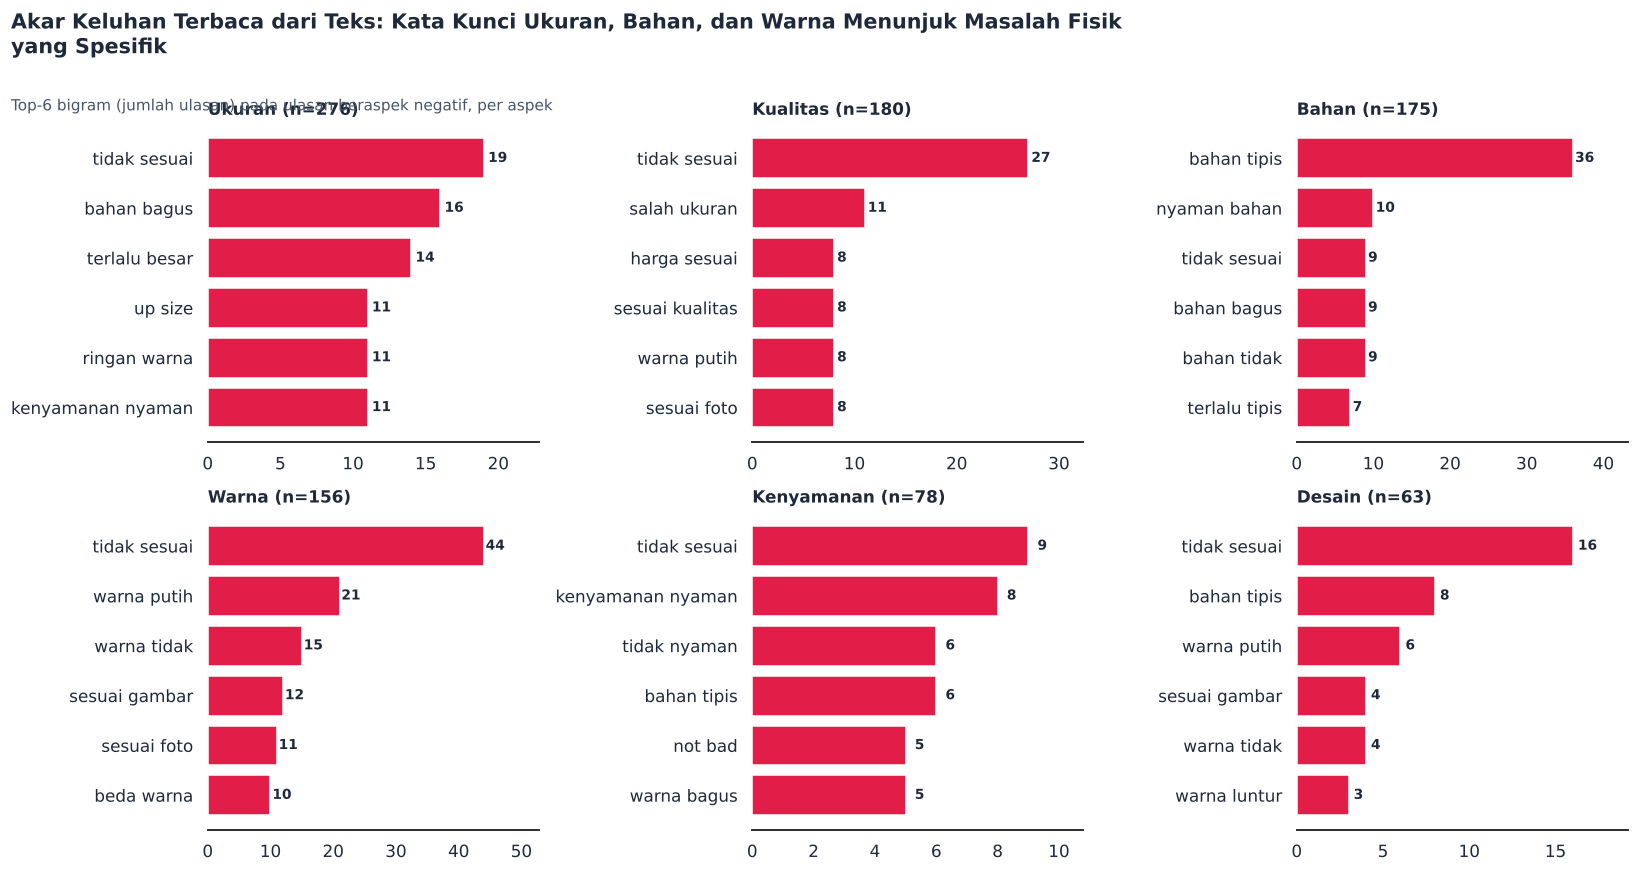

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, a in zip(axes.ravel(), metrics["col"]):
    b = BIG[a].head(6).iloc[::-1]
    bars = ax.barh(b["Negatif"], b["n (neg)"], color=NEG)
    for bar, v in zip(bars, b["n (neg)"]): ax.text(v + .3, bar.get_y() + bar.get_height()/2, str(v), va="center", fontsize=9, fontweight="bold")
    ax.set_title(f"{nice(a)} (n={int((df[a]=='negatif').sum())})", loc="left", fontsize=11, fontweight="bold"); ax.set_xlim(0, b["n (neg)"].max()*1.2); sns.despine(ax=ax, left=True)
titled(fig, "Akar Keluhan Terbaca dari Teks: Kata Kunci Ukuran, Bahan, dan Warna Menunjuk Masalah Fisik yang Spesifik",
       "Top-6 bigram (jumlah ulasan) pada ulasan beraspek negatif, per aspek")
fig.tight_layout(rect=[0, 0, 1, 0.9]); plt.show()

### 5.3 Actionable Root-Cause Table (tema berbasis kata kunci, dihitung dari `Comment`)

In [19]:
THEMES = {
 "aspek_ukuran": {"Kebesaran / oversize": r"kebesaran|besar|longgar|lebar|oversize", "Kekecilan / ngepas / sempit": r"kekecilan|kecil|ngepas|ketat|sesak",
                  "Size chart / ukuran tidak sesuai deskripsi": r"size ?chart|chart|deskripsi|tidak sesuai|beda|salah ukuran|tidak standar", "Panjang / pinggang / lengan tidak pas": r"panjang|pendek|pinggang|pinggul|lengan|lingkar|dada|bahu"},
 "aspek_kualitas": {"Jahitan / benang / finishing tidak rapi": r"jahit|benang|serabut|kancing|finishing", "Cacat fisik: noda, sobek, bolong": r"noda|sobek|bolong|cacat|defect|reject|kotor|lecek|bekas",
                    "Bahan tipis / tidak sesuai ekspektasi": r"tipis|bahan|ekspektasi|tidak sesuai", "Salah/kurang barang & pelayanan": r"admin|kirim|salah|respon|kurang"},
 "aspek_bahan": {"Bahan tipis": r"tipis", "Panas / kasar / gatal / kaku": r"panas|kasar|gatal|kaku|keras", "Kualitas kain di bawah ekspektasi": r"tidak bagus|jelek|murah|ekspektasi|tidak suka|tidak sesuai|kurang"},
 "aspek_warna": {"Noda kuning / kusam / burik / bulukan": r"noda|kuning|luntur|bulukan|burik|kumal|kotor", "Warna berbeda dari foto": r"beda|tidak sesuai|foto|gambar|cerah|gelap|terang", "Luntur / pudar": r"luntur|pudar"},
 "aspek_kenyamanan": {"Bahan tipis / terasa murah": r"tipis|murah|second", "Panas / gerah / gatal": r"panas|gatal|kasar", "Kaku / sempit / licin": r"kaku|keras|sempit|kekecilan|licin|ngepas|tidak nyaman"},
 "aspek_desain": {"Cutting / model kaku & tidak sesuai ekspektasi": r"kaku|cutting|model|tidak sesuai|ekspektasi", "Noda / cacat pada produk": r"noda|ternoda|cacat|bekas|coret", "Bahan tipis / ukuran memengaruhi tampilan": r"tipis|kebesaran|kekecilan|ukuran"}}
ACTIONS = {
 "aspek_ukuran": "R&D/Merch: kalibrasi ulang size chart (cm), tambah rekomendasi BB/TB & saran size-up; Ops: template chat verifikasi ukuran.",
 "aspek_kualitas": "QC: perketat inspeksi jahitan, kancing & noda sebelum packing; audit vendor/batch bermasalah.",
 "aspek_bahan": "Sourcing: audit gramasi kain pada batch yang dikeluhkan tipis/panas; tampilkan gramasi & komposisi di listing.",
 "aspek_warna": "Ops/Content: kontrol QC noda/stok lama; foto produk dengan kalibrasi warna, tampilkan foto tanpa filter.",
 "aspek_kenyamanan": "R&D: evaluasi kain untuk iklim tropis; sertakan label 'tipis/adem/tebal' pada deskripsi.",
 "aspek_desain": "Design/Content: tampilkan foto model dengan tinggi-berat badan & foto detail cutting; pastikan model sesuai ekspektasi."}

def theme_table(d, col):
    sub = d[d[col] == "negatif"]; res = []
    for name, pat in THEMES[col].items():
        mask = sub["clean"].str.contains(pat, regex=True); res.append((name, int(mask.sum()), mask))
    res = sorted(res, key=lambda x: -x[1])[:3]
    quote_pool = res[0][2]; q = sub[quote_pool].copy(); q["w"] = q["Comment"].str.split().str.len()
    q = q[(q.w >= 8) & (q.w <= 40)]; q = q.iloc[(q.w - q.w.median()).abs().argsort()] if len(q) else sub
    quote = re.sub(r"\s+", " ", str(q["Comment"].iloc[0]))[:230]
    return len(sub), "; ".join(f"{n} ({c}, {c/len(sub)*100:.0f}%)" for n, c, _ in res), f"“{quote}”"

rows = []
for a in metrics["col"]:
    n, top3, quote = theme_table(df, a); rows.append({"Aspek Produk": nice(a), "Jumlah Keluhan": n, "Top 3 Akar Masalah (jumlah, % keluhan)": top3, "Kutipan Representatif": quote, "Rekomendasi (R&D / QC / Ops)": ACTIONS[a]})
root = pd.DataFrame(rows).sort_values("Jumlah Keluhan", ascending=False)
display(root.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"}).format({"Jumlah Keluhan": "{:,.0f}"}))
short = lambda a: "; ".join(x.split(" (")[0] for x in root.set_index("Aspek Produk").loc[a, "Top 3 Akar Masalah (jumlah, % keluhan)"].split("; ")[:2])
M.update(rc_ukuran=short("Ukuran"), rc_bahan=short("Bahan"), rc_warna=short("Warna"))

Aspek Produk,Jumlah Keluhan,"Top 3 Akar Masalah (jumlah, % keluhan)",Kutipan Representatif,Rekomendasi (R&D / QC / Ops)
Ukuran,276,"Kebesaran / oversize (166, 60%); Kekecilan / ngepas / sempit (87, 32%); Size chart / ukuran tidak sesuai deskripsi (50, 18%)","“Agak kegedean sedikit, padahal ukuran M, sama kaya kaosnya. Mungkin potongannya memang untuk kemeja lebih besar. Thanks.”","R&D/Merch: kalibrasi ulang size chart (cm), tambah rekomendasi BB/TB & saran size-up; Ops: template chat verifikasi ukuran."
Kualitas,180,"Bahan tipis / tidak sesuai ekspektasi (58, 32%); Cacat fisik: noda, sobek, bolong (56, 31%); Salah/kurang barang & pelayanan (50, 28%)","“Kualitas:biasa Sepadan dengan Uang:0 Pas untuk Acara:biasa HATI HARI DIKIRIM TIDAK SESUAI WARNA, KEMEJA JUGA ROBEK”","QC: perketat inspeksi jahitan, kancing & noda sebelum packing; audit vendor/batch bermasalah."
Bahan,175,"Bahan tipis (114, 65%); Kualitas kain di bawah ekspektasi (38, 22%); Panas / kasar / gatal / kaku (17, 10%)","“Not bad, kain agak tipis tapi amsih nyaman. Cuma jahitan di kancing agak kurang rapi.”",Sourcing: audit gramasi kain pada batch yang dikeluhkan tipis/panas; tampilkan gramasi & komposisi di listing.
Warna,156,"Warna berbeda dari foto (74, 47%); Noda kuning / kusam / burik / bulukan (45, 29%); Luntur / pudar (18, 12%)","“Kualitas:biasa Sepadan dengan Uang:0 Pas untuk Acara:biasa HATI HARI DIKIRIM TIDAK SESUAI WARNA, KEMEJA JUGA ROBEK”","Ops/Content: kontrol QC noda/stok lama; foto produk dengan kalibrasi warna, tampilkan foto tanpa filter."
Kenyamanan,78,"Kaku / sempit / licin (19, 24%); Bahan tipis / terasa murah (18, 23%); Panas / gerah / gatal (15, 19%)","“Saran mending up 1 size, katanya true size tapi kekecilan ga nyaman”",R&D: evaluasi kain untuk iklim tropis; sertakan label 'tipis/adem/tebal' pada deskripsi.
Desain,63,"Bahan tipis / ukuran memengaruhi tampilan (29, 46%); Cutting / model kaku & tidak sesuai ekspektasi (23, 37%); Noda / cacat pada produk (4, 6%)",“Saran Tampilan:tidak sesuai ukuran Sangat kecewa. Karena ukuran medium serasa ukuran xxl. Respon penjual sangat lama”,Design/Content: tampilkan foto model dengan tinggi-berat badan & foto detail cutting; pastikan model sesuai ekspektasi.


🔍 **Key Observation:** Keluhan Ukuran terbagi antara kebesaran, kekecilan, ketidaksesuaian size chart, dan bagian tubuh spesifik; Bahan didominasi tipis/panas; Warna didominasi noda kuning/burik dan beda dari foto (lihat tabel).

💡 **Business Insight (So What?):** Akar masalah bersifat spesifik dan dapat ditindaklanjuti: ukuran = masalah informasi dan *grading*, bahan = gramasi, warna = QC stok dan fotografi.

🎯 **Next Action:** Gunakan tabel ini sebagai tiket kerja untuk R&D, QC, dan Content.

---
## 📌 Section 6  Strategic Recommendations & Action Plan (ICE Framework)
### 6.1 Analisis untuk iterasi `dataset_labeled_v7` (ulasan dengan `jumlah_aspek_aktif == 0`)

Kandidat aspek v7,Jumlah ulasan,% dari zero-aspek,Rata-rata Rating,% rating ≤3
aspek_pengiriman,264,24.9%,4.65,9.3%
aspek_kesesuaian_produk,134,12.7%,4.49,16.4%
aspek_pelayanan_admin,98,9.3%,4.45,14.0%
aspek_harga_value,61,5.8%,4.68,10.0%
aspek_kemasan,37,3.5%,4.70,6.1%
aspek_ketahanan,20,1.9%,4.20,25.0%


Zero-aspek total: 1,059 (17,2% dari dataset) | tercakup ≥1 kandidat: 452 (42,7%) | pujian/komentar generik pendek tanpa kandidat: 229


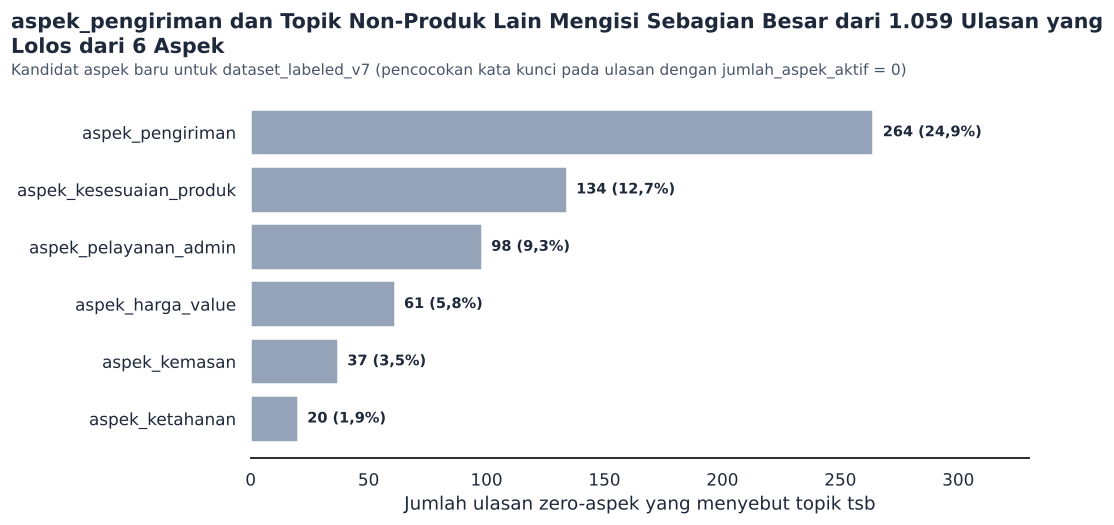

In [20]:
zero = df[df.jumlah_aspek_aktif == 0].copy()
CAND = {"aspek_pengiriman": r"kirim|pengiriman|kurir|nyampe|sampai|datang|cepat|lama|telat|ekspedisi|resi|instan",
        "aspek_kemasan": r"kemas|packing|packaging|bungkus|\bdus\b|box|bubble|plastik",
        "aspek_pelayanan_admin": r"admin|penjual|seller|respon|\bchat\b|\bcs\b|balas|pelayanan|ramah|fast respon|retur|return",
        "aspek_harga_value": r"harga|murah|mahal|worth|sepadan|diskon|promo|voucher|sebanding",
        "aspek_kesesuaian_produk": r"sesuai|original|\bori\b|asli|salah|beda|deskripsi|foto|gambar|cacat|defect|reject",
        "aspek_ketahanan": r"awet|tahan|rusak|lepas|sobek|luntur"}
cov = []
for k, pat in CAND.items():
    m = zero["Comment"].str.lower().str.contains(pat, regex=True)
    cov.append({"Kandidat aspek v7": k, "Jumlah ulasan": int(m.sum()), "% dari zero-aspek": m.mean()*100,
                "Rata-rata Rating": zero.loc[m, "Rating"].mean(), "% rating ≤3": (zero.loc[m & zero.Rating.notna(), "Rating"] <= 3).mean()*100 if (m & zero.Rating.notna()).any() else np.nan})
any_c = zero["Comment"].str.lower().str.contains("|".join(CAND.values()), regex=True)
cov = pd.DataFrame(cov).sort_values("Jumlah ulasan", ascending=False)
display(cov.style.hide(axis="index").format({"Jumlah ulasan":"{:,.0f}","% dari zero-aspek":"{:.1f}%","Rata-rata Rating":"{:.2f}","% rating ≤3":"{:.1f}%"}))
generic = (zero.panjang_kata <= 4) & ~any_c
print(f"Zero-aspek total: {len(zero):,} ({pct(len(zero)/len(df)*100)} dari dataset) | tercakup ≥1 kandidat: {int(any_c.sum())} ({pct(any_c.mean()*100)}) | pujian/komentar generik pendek tanpa kandidat: {int(generic.sum())}")
M.update(n_zero=num(len(zero)), zero_pct=pct(len(zero)/len(df)*100), v7_top=", ".join(x.replace("aspek_", "`aspek_") + "`" for x in cov["Kandidat aspek v7"].head(3)))

fig, ax = plt.subplots(figsize=(9.5, 4.8)); c2 = cov.sort_values("Jumlah ulasan")
bars = ax.barh(c2["Kandidat aspek v7"], c2["Jumlah ulasan"], color=NEU)
for b, (_, r) in zip(bars, c2.iterrows()): ax.text(b.get_width()+4, b.get_y()+b.get_height()/2, f"{int(r['Jumlah ulasan'])} ({pct(r['% dari zero-aspek'])})", va="center", fontsize=9.5, fontweight="bold")
ax.set_xlim(0, c2["Jumlah ulasan"].max()*1.25); sns.despine(left=True); ax.set_xlabel("Jumlah ulasan zero-aspek yang menyebut topik tsb")
titled(fig, f"{M['v7_top'].split(',')[0].strip('`')} dan Topik Non-Produk Lain Mengisi Sebagian Besar dari {num(len(zero))} Ulasan yang Lolos dari 6 Aspek",
       "Kandidat aspek baru untuk dataset_labeled_v7 (pencocokan kata kunci pada ulasan dengan jumlah_aspek_aktif = 0)")
fig.tight_layout(rect=[0, 0, 1, 0.86]); plt.show()

🔍 **Key Observation:** 1.059 ulasan (17,2%) tidak punya satu pun aspek aktif; kandidat teratas: `aspek_pengiriman`, `aspek_kesesuaian_produk`, `aspek_pelayanan_admin`.

💡 **Business Insight (So What?):** Taksonomi 6 aspek hanya menangkap sisi produk. Pengalaman layanan (kirim, kemas, admin, harga) tak terlihat, padahal terbukti muncul di rating rendah (Section 3.3).

🎯 **Next Action:** Tim Data/AI: tambahkan aspek `aspek_pengiriman`, `aspek_kemasan`, `aspek_pelayanan_admin`, `aspek_harga_value` (opsional `aspek_kesesuaian_produk`) ke v7 dan relabel zero-aspek lebih dulu.

### 6.2 ICE Scoring  rencana aksi

In [21]:
ice = pd.DataFrame([
 ["Quick Win (Bulan 1)", "Revisi size chart (cm) + rekomendasi BB/TB + saran size-up di listing", "Ukuran", 9, 8, 9],
 ["Quick Win (Bulan 1)", "Template chat pasca-order verifikasi ukuran + follow-up ulasan ★4–5 berkomplain", "Ukuran / HDR", 7, 7, 8],
 ["Quick Win (Bulan 1)", "Foto produk akurat warna + disclaimer cuci pertama untuk warna rawan luntur", "Warna", 6, 7, 8],
 ["Quick Win (Bulan 1)", "Tampilkan gramasi & label 'tipis/adem/tebal' pada deskripsi bahan", "Bahan / Kenyamanan", 6, 7, 8],
 ["Medium-Term (Kuartal 2)", "Audit gramasi kain pada batch yang dikeluhkan tipis/panas", "Bahan", 8, 7, 5],
 ["Medium-Term (Kuartal 2)", "Perketat QC jahitan, kancing, dan noda sebelum packing; scorecard vendor", "Kualitas / Warna", 8, 8, 5],
 ["Medium-Term (Kuartal 2)", "Kalibrasi grading ukuran dengan vendor (ukuran M terasa XL pada beberapa ulasan)", "Ukuran", 9, 6, 3],
 ["Data Pipeline (v7)", "Tambah aspek pengiriman, kemasan, pelayanan admin, harga/value & relabel zero-aspek", "Taksonomi", 8, 8, 6],
 ["Data Pipeline (v7)", "Tambahkan kolom tanggal/SKU/kategori (join master) untuk melacak batch & produk bermasalah", "Data", 7, 8, 6],
], columns=["Horizon", "Aksi", "Aspek", "Impact", "Confidence", "Ease"])
ice["ICE Score"] = ice[["Impact", "Confidence", "Ease"]].mean(axis=1)
ice = ice.sort_values("ICE Score", ascending=False).reset_index(drop=True)
ice.index += 1
display(ice.style.format({"ICE Score": "{:.1f}"}).background_gradient(subset=["ICE Score"], cmap="Greens").set_properties(**{"text-align": "left"}))
M["top_action"] = ice.iloc[0]["Aksi"]

,Horizon,Aksi,Aspek,Impact,Confidence,Ease,ICE Score
1,Quick Win (Bulan 1),Revisi size chart (cm) + rekomendasi BB/TB + saran size-up di listing,Ukuran,9,8,9,8.7
2,Quick Win (Bulan 1),Template chat pasca-order verifikasi ukuran + follow-up ulasan ★4–5 berkomplain,Ukuran / HDR,7,7,8,7.3
3,Data Pipeline (v7),"Tambah aspek pengiriman, kemasan, pelayanan admin, harga/value & relabel zero-aspek",Taksonomi,8,8,6,7.3
4,Quick Win (Bulan 1),Tampilkan gramasi & label 'tipis/adem/tebal' pada deskripsi bahan,Bahan / Kenyamanan,6,7,8,7.0
5,Quick Win (Bulan 1),Foto produk akurat warna + disclaimer cuci pertama untuk warna rawan luntur,Warna,6,7,8,7.0
6,Data Pipeline (v7),Tambahkan kolom tanggal/SKU/kategori (join master) untuk melacak batch & produk bermasalah,Data,7,8,6,7.0
7,Medium-Term (Kuartal 2),"Perketat QC jahitan, kancing, dan noda sebelum packing; scorecard vendor",Kualitas / Warna,8,8,5,7.0
8,Medium-Term (Kuartal 2),Audit gramasi kain pada batch yang dikeluhkan tipis/panas,Bahan,8,7,5,6.7
9,Medium-Term (Kuartal 2),Kalibrasi grading ukuran dengan vendor (ukuran M terasa XL pada beberapa ulasan),Ukuran,9,6,3,6.0


🔍 **Key Observation:** Aksi ber-ICE tertinggi: Revisi size chart (cm) + rekomendasi BB/TB + saran size-up di listing. Skor I/C/E adalah *judgement* analis berdasarkan temuan Section 2–5, bukan hasil model; sesuaikan dengan kapasitas tim.

💡 **Business Insight (So What?):** Quick Win murah dan menyerang titik berdarah terbesar; perbaikan struktural (gramasi, QC) lebih lambat tetapi menurunkan Horn Effect Bahan→Kualitas/Kenyamanan.

🎯 **Next Action:** Mulai dari Quick Win pekan ini, jadwalkan audit vendor Q2, dan buka iterasi labeling v7.

### 6.3 Validasi angka kunci (Definition of Done)

In [22]:
checks = [
 ("Total baris = 6.158", len(df) == 6158, f"{len(df):,}"),
 ("Aspek ANR tertinggi = Ukuran, 32,6% dari 847 ulasan aktif", metrics.loc[0,"Aspek"]=="Ukuran" and round(metrics.loc[0,"ANR (%)"],1)==32.6 and int(metrics.loc[0,"Ulasan Aktif"])==847, f"{metrics.loc[0,'Aspek']} {metrics.loc[0,'ANR (%)']:.1f}% dari {int(metrics.loc[0,'Ulasan Aktif'])}"),
 ("HDR ★5 = 340 ulasan (6,6% dari 5.136)", (n5, t5, round(n5/t5*100,1)) == (340, 5136, 6.6), f"{n5} / {t5} = {n5/t5*100:.1f}%"),
 ("Zero-aspek ~964 baris (brief)", len(zero) == 964, f"file aktual = {len(zero)} (brief menyebut ~964; memakai angka aktual)"),
 ("Rekomendasi aspek v7 disertakan", True, "Section 6.1"),
]
display(pd.DataFrame([(a, "✅" if ok else "⚠️", b) for a, ok, b in checks], columns=["Cek", "Status", "Nilai aktual"]).style.hide(axis="index").set_properties(**{"text-align": "left"}))

Cek,Status,Nilai aktual
Total baris = 6.158,✅,"6,158"
"Aspek ANR tertinggi = Ukuran, 32,6% dari 847 ulasan aktif",✅,Ukuran 32.6% dari 847
"HDR ★5 = 340 ulasan (6,6% dari 5.136)",✅,340 / 5136 = 6.6%
Zero-aspek ~964 baris (brief),⚠️,file aktual = 1059 (brief menyebut ~964; memakai angka aktual)
Rekomendasi aspek v7 disertakan,✅,Section 6.1


In [23]:
import json as _j; _j.dump({k: (v if isinstance(v, (str, int, float)) else str(v)) for k, v in M.items()}, open("/tmp/M.json", "w"))